# Tái lập kết quả paper **MAKAR** (EMNLP 2025) trên Kaggle

> **MAKAR: a Multi-Agent framework based Knowledge-Augmented Reasoning for Grounded Multimodal Named Entity Recognition**
> Lin et al., EMNLP 2025, trang 6110–6130 · Code: <https://github.com/Nikol-coder/MAKAR>

**Bài toán GMNER:** cho một tweet gồm văn bản $T$ và ảnh $I$, trích xuất tập bộ ba $F=\{(e_i, t_i, c_i)\}$: thực thể $e_i$, loại $t_i$, và vùng ảnh $c_i$ (bounding box, hoặc `None` nếu thực thể không xuất hiện trong ảnh).

**MAKAR gồm 3 agent:**

| Agent | Vai trò | Cài đặt trong paper |
|---|---|---|
| ① **KEA** – Knowledge Enhancement | MLLM sinh *auxiliary knowledge* (dựa trên 3 ví dụ gần nhất trong Query Set, chọn bằng BGE-VL) → ghép vào câu → RoBERTa + CRF gán nhãn NER | Eq. 3–6 |
| ② **ECA** – Entity Correction | Với thực thể có độ tin cậy thấp ($\min(p_b,p_t)<\tau=0.5$): web search 3 trang → tóm tắt → MLLM sửa biên/loại thực thể | Eq. 7 |
| ③ **ERGA** – Entity Reasoning Grounding | Qwen2.5-VL suy luận Chain-of-Thought `<think>…</think><answer>[x1,y1,x2,y2]</answer>`; huấn luyện 2 pha: SFT (3k mẫu dễ) → GRPO (3k mẫu khó) | Eq. 8–15 |

**Chỉ số:** MNER (biên + loại), EEG (biên + vùng ảnh, IoU > 0.5), MNERG (cả bộ ba) – F1 theo Eq. 16–20.

## Phạm vi tái lập (đọc trước khi chạy)

Paper huấn luyện trên **8×A800**; Kaggle chỉ có **2×T4 (16 GB)**, 12 giờ/phiên. Notebook vì vậy tái lập *trung thực nhất có thể* trong giới hạn này:

| Thành phần | Paper | Notebook này |
|---|---|---|
| Dữ liệu Twitter-GMNER / Twitter-FMNERG | ✔ | ✔ dữ liệu gốc của NUSTM (ảnh + box) – **tái lập Table 2** |
| KEA: auxiliary knowledge do MLLM sinh | Qwen/LLaMA + BGE-VL top-3 | ✔ dùng **đúng file auxiliary knowledge tác giả công bố** (sinh lại cần chạy MLLM ~10k lần) |
| KEA: bộ gán nhãn NER + CRF | XLM-RoBERTa-large + CRF (AdaSeq) | ✔ **huấn luyện lại từ đầu** (PyTorch thuần, cùng siêu tham số; số epoch giảm để vừa thời gian) |
| Ablation *w/o KEA* | ✔ | ✔ huấn luyện song song mô hình không có auxiliary knowledge (GPU thứ 2) |
| ECA: web search + MLLM sửa lỗi | Bing + ReaderLM-v2 + Qwen2.5-VL-7B | ✔ thay Bing (đã ngừng) bằng DuckDuckGo snippets; Qwen2.5-VL-7B-Instruct |
| ERGA: SFT + GRPO | 8×A800 | ✘ không huấn luyện lại (quá lớn) → dùng **checkpoint chính thức MAKAR-3B/7B**; ✔ minh họa reward + advantage của GRPO (Eq. 9–12) trên mẫu thật |
| Baseline Qwen2.5-VL *Raw* (Table 5) | ✔ | ✔ chạy cùng prompt |
| Table 3, Table 4, Table 5 | ✔ | ✔ một phần (xem bảng tổng hợp cuối notebook) |

**Thiết lập Kaggle:** *Settings → Accelerator = GPU T4 ×2*, *Internet = On*. Chạy **Run All**.
Thời gian: Kaggle **dừng cứng mọi phiên sau 12 h** và khi đó mất toàn bộ kết quả. Vì vậy notebook có ngân sách `TIME_BUDGET_H = 11` giờ và trần thời gian cho từng bước (`NER_MAX_H`, `ECA_MAX_H`, `RAW_MAX_H`). Hết giờ, notebook tự dừng gọn và lưu những gì đã chạy.
**Nếu chưa chạy xong trong một lần:** *Save Version* (Save & Run All) → mở phiên mới → *Add Input* chọn Output của version vừa rồi → *Run All*. Notebook tự nạp kết quả cũ và chạy tiếp (NER đã train sẽ không train lại, grounding chạy tiếp từ request còn thiếu).
Đổi `DATASET = "FMNERG"` rồi chạy lại để có cột FMNERG (kết quả của mỗi lần chạy được lưu vào `/kaggle/working/`).

In [1]:
# ============================== CẤU HÌNH ==============================
import time; T_START = time.time()
# Kaggle dừng cứng mọi phiên sau 12 h (mất hết kết quả). Notebook tự dừng gọn trước mốc này; mỗi bước có trần thời gian riêng.
# Nếu chưa xong: Save Version -> phiên mới "Add Input" = Output của version trước -> Run All: notebook tự chạy tiếp.
TIME_BUDGET_H    = 11.0
NER_MAX_H        = 4.5            # trần thời gian huấn luyện NER (2 mô hình chạy song song)
ECA_MAX_H        = 1.0            # trần thời gian ECA (search + 2 lượt MLLM)
RAW_MAX_H        = 1.0            # trần thời gian baseline Raw
DATASET          = "FMNERG"        # "GMNER" (4 loại thô) hoặc "FMNERG" (51 loại mịn)

# --- KEA (NER) ---
NER_ENCODER      = "FacebookAI/xlm-roberta-large"   # như config AdaSeq của tác giả
NER_EPOCHS       = 8              # config gốc: 25 epoch -> giảm cho vừa Kaggle (dừng sớm nếu chạm NER_MAX_H)
NER_LR           = 7e-6           # config gốc
GMNER_TRAIN_MODE = "gmner7000"    # "gmner7000": đúng 7000 câu train của GMNER (Table 2)
                                  # "full": toàn bộ 28k câu tác giả dùng (có trộn Twitter-15/17, chậm 4x)
RUN_NO_KEA       = True           # ablation w/o KEA (chạy song song trên GPU thứ 2)

# --- ECA ---
RUN_ECA          = True
ECA_MODEL        = "Qwen/Qwen2.5-VL-3B-Instruct"     # paper: 7B; 7B không vừa 1 T4 (fp16) nên chạy rất chậm -> mặc định 3B
TAU              = 0.5            # ngưỡng tin cậy (paper: 0.5)
ECA_NUM_PAGES    = 3              # paper: 3 trang web
ECA_MAX_SENT     = 300            # số câu tin cậy thấp nhất đưa vào ECA (None = tất cả)
ECA_ALLOW_NEW    = False          # True: chấp nhận cả thực thể mới mà MLLM đề xuất

# --- ERGA ---
MAKAR_CKPT       = "soliton110/MAKAR-3B"            # hoặc "soliton110/MAKAR-7B" (chậm hơn ~2x)
RAW_BASELINE     = "Qwen/Qwen2.5-VL-3B-Instruct"    # Table 5 "Raw"; None để bỏ qua
RAW_MAX_SENT     = 300            # baseline Raw chạy trên tập con ngẫu nhiên (so với MAKAR trên cùng tập con)
GRPO_DEMO_N      = 5              # số response / nhóm trong demo GRPO (config tác giả: n=5)
BACKEND          = "auto"         # "auto": vLLM nếu cài được, nếu không dùng transformers (chia đều cho 2 GPU)
MLLM_DTYPE       = "half"         # T4 không có bf16. Nếu output lỗi (chuỗi "!!!!", sai định dạng) -> "float32" (chỉ vừa với model 3B)
TP               = 2              # tensor parallel trên 2×T4

DELETE_MODELS    = True           # xóa model MLLM sau khi dùng để tiết kiệm đĩa
QUICK_TEST       = False          # True: chạy thử nhanh (1 epoch, 200 câu test) để kiểm tra pipeline
# ======================================================================
import os
ON_KAGGLE = os.path.exists("/kaggle")
WORK  = "/kaggle/working" if ON_KAGGLE else os.path.abspath("work")    # kết quả (được lưu lại)
CACHE = "/tmp/makar" if ON_KAGGLE else os.path.abspath("cache")        # model, ảnh (lớn, không cần lưu)
for d in (WORK, CACHE): os.makedirs(d, exist_ok=True)
if QUICK_TEST: NER_EPOCHS, ECA_MAX_SENT = 1, 30
RUN_DIR = f"{WORK}/{DATASET}"; os.makedirs(RUN_DIR, exist_ok=True)
os.chdir(WORK)
import sys; sys.path.insert(0, WORK)
import shutil, glob
DEADLINE = T_START + TIME_BUDGET_H * 3600
def hours_left(): return (DEADLINE - time.time()) / 3600
STOP = False                       # True khi hết ngân sách thời gian -> các bước sau tự bỏ qua
SKIP_MSG = "⏭ Bỏ qua: hết ngân sách thời gian. Save Version, rồi chạy version mới với Output của version này làm Input để chạy tiếp."
# Nạp kết quả của lần chạy trước (Output của version cũ được gắn vào /kaggle/input)
if ON_KAGGLE:
    prev = [d for d in glob.glob(f"/kaggle/input/**/{DATASET}", recursive=True) if os.path.isdir(f"{d}/ner_kea")]
    if prev:
        shutil.copytree(prev[0], RUN_DIR, dirs_exist_ok=True); print("↻ chạy tiếp từ", prev[0])
    for f in glob.glob("/kaggle/input/**/results_*.json", recursive=True):
        if not os.path.exists(f"{WORK}/{os.path.basename(f)}"): shutil.copy(f, WORK)
print("WORK =", WORK, "| CACHE =", CACHE, "| RUN_DIR =", RUN_DIR, f"| đĩa trống: {shutil.disk_usage(CACHE).free / 1e9:.0f} GB")

WORK = /kaggle/working | CACHE = /tmp/makar | RUN_DIR = /kaggle/working/FMNERG | đĩa trống: 1149 GB


In [2]:
# Cài thư viện (~1 phút). Dùng torch/transformers có sẵn của Kaggle.
# Không cài vLLM: Kaggle hiện chạy Python 3.13, vLLM 0.8.5 (bản cuối hỗ trợ T4 qua engine V0) chỉ hỗ trợ Python < 3.13,
# còn các bản vLLM mới sẽ cài đè PyTorch của Kaggle. Suy luận MLLM dùng transformers, chia đều cho 2 GPU.
!pip install -q modelscope gdown ddgs
import subprocess, sys
print(sys.version.split()[0])
for mod in ("torch", "transformers", "modelscope", "gdown", "ddgs"):
    r = subprocess.run([sys.executable, "-c", f"import {mod}; print({mod}.__version__)"], capture_output=True, text=True)
    print(f"{mod:12s}", r.stdout.strip() if r.returncode == 0 else "LỖI -> " + (r.stderr.strip().splitlines() or ["?"])[-1])
!nvidia-smi --query-gpu=name,memory.total --format=csv
import subprocess
N_GPU = len(subprocess.run("nvidia-smi -L", shell=True, capture_output=True, text=True).stdout.strip().splitlines())
TP = min(TP, max(N_GPU, 1)); print("Số GPU:", N_GPU, "| TP =", TP)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 1.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.9/47.9 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 237.2/237.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 113.4 MB/s eta 0:00:00
3.13.15
torch        2.11.0+cu128
transformers 5.16.1
modelscope   1.40.2
gdown        5.2.2
ddgs         9.16.0
name, memory.total [MiB]
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
Số GPU: 2 | TP = 2


### Mã nguồn dùng chung
Ba file dưới đây được ghi ra đĩa để các tiến trình con (huấn luyện, suy luận vLLM) dùng lại — mỗi bước GPU chạy trong một tiến trình riêng để giải phóng hoàn toàn bộ nhớ khi kết thúc.
* `makar_common.py`: đọc dữ liệu, chỉ số Eq. 16–20, prompt grounding (đúng nguyên văn dữ liệu huấn luyện ERGA), reward GRPO (Eq. 9–10, theo `EasyR1/examples/score_function/reason_grounding.py`).
* `train_mner.py`: KEA — XLM-R + CRF (Eq. 3–6), trả về thêm xác suất biên (marginal) của CRF để làm độ tin cậy cho ECA.
* `mllm_infer.py`: suy luận Qwen2.5-VL theo lô (vLLM nếu có, nếu không dùng transformers).

In [3]:
%%writefile makar_common.py
# makar_common.py -- shared data loading + GMNER metrics (Eq. 16-20 of the MAKAR paper)
import os, re, json, xml.etree.ElementTree as ET
from collections import defaultdict

# ---------------------------------------------------------------- data readers
def read_makar_conll(path):
    """MAKAR/AdaSeq file: `word<TAB>label`; tokens labelled X after <EOS> are the
    auxiliary knowledge generated by the MLLM (output of the Knowledge Enhancement Agent)."""
    sents, cur = [], []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.rstrip('\r\n')
            if not line.strip():
                if cur: sents.append(cur); cur = []
                continue
            p = line.split('\t') if '\t' in line else line.split(' ')
            cur.append((p[0], p[-1]))
    if cur: sents.append(cur)
    out = []
    for s in sents:
        words = [w for w, l in s if l != 'X']
        labels = [l for w, l in s if l != 'X']
        aux = [w for w, l in s if l == 'X' and w != '<EOS>']
        out.append({'words': words, 'labels': labels, 'aux': aux})
    return out


def read_nustm_conll(path, col=1):
    """NUSTM GMNER/FMNERG file: `IMGID:xxx` line, then `word<TAB>label[<TAB>fine]`."""
    out, cur = [], None
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.rstrip('\r\n')
            if line.startswith('IMGID:'):
                cur = {'img': line[6:].strip(), 'words': [], 'labels': []}; continue
            if not line.strip():
                if cur and cur['words']: out.append(cur)
                cur = None; continue
            p = line.split('\t')
            cur['words'].append(p[0]); cur['labels'].append(p[col])
    if cur and cur['words']: out.append(cur)
    return out


def bio_spans(labels):
    """BIO tags -> list of (start, end_exclusive, type). A stray I- starts a new span."""
    spans, s, t = [], None, None
    for i, l in enumerate(list(labels) + ['O']):
        if l == 'O' or l.startswith('B-') or (l.startswith('I-') and l[2:] != t):
            if s is not None: spans.append((s, i, t))
            s, t = (i, l[2:]) if l[:2] in ('B-', 'I-') else (None, None)
    return spans


def read_xml(path):
    """Pascal-VOC xml -> ({entity_name: [[x1,y1,x2,y2], ...]}, (w, h))."""
    boxes, size = defaultdict(list), None
    if not os.path.exists(path): return boxes, size
    root = ET.parse(path).getroot()
    sz = root.find('size')
    if sz is not None: size = (int(sz.find('width').text), int(sz.find('height').text))
    for o in root.findall('object'):
        b = o.find('bndbox')
        boxes[o.find('name').text.strip()].append(
            [int(float(b.find(k).text)) for k in ('xmin', 'ymin', 'xmax', 'ymax')])
    return boxes, size


def load_gold(txt_path, xml_dir, col=1):
    """Gold triples per tweet: {(start,end): (type, [boxes])}; empty box list = ungroundable."""
    data = read_nustm_conll(txt_path, col)
    for s in data:
        bx, size = read_xml(os.path.join(xml_dir, s['img'] + '.xml'))
        s['size'] = size
        s['gold'] = {}
        for a, b, t in bio_spans(s['labels']):
            name = ' '.join(s['words'][a:b])
            s['gold'][(a, b)] = (t, bx.get(name, []))
    return data


def build_image_index(root):
    idx = {}
    for dp, _, fs in os.walk(root):
        for fn in fs:
            if fn.lower().endswith(('.jpg', '.jpeg', '.png', '.gif')):
                idx.setdefault(os.path.splitext(fn)[0], os.path.join(dp, fn))
    return idx

# ---------------------------------------------------------------- metrics
def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    ua = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / ua if ua > 0 else 0.0


def region_correct(pred_box, gold_boxes, thr=0.5):
    """Eq. 17: both None, or IoU(pred, any gold box) > 0.5."""
    if pred_box is None: return len(gold_boxes) == 0
    return any(iou(pred_box, g) > thr for g in gold_boxes)


def prf(n_correct, n_pred, n_gold):
    p = n_correct / n_pred if n_pred else 0.0
    r = n_correct / n_gold if n_gold else 0.0
    f = 2 * p * r / (p + r) if p + r else 0.0
    return {'P': 100 * p, 'R': 100 * r, 'F1': 100 * f}


def evaluate(gold_data, preds):
    """preds[i] = list of (start, end, type, box_or_None)  (box may be absent -> MNER only).
    Returns F1 for MNER (C_e & C_t), EEG (C_e & C_c), MNERG (C_e & C_t & C_c) -- Eq. 16-20."""
    n_gold = sum(len(s['gold']) for s in gold_data)
    n_pred = sum(len(p) for p in preds)
    c = {'MNER': 0, 'EEG': 0, 'MNERG': 0}
    for s, P in zip(gold_data, preds):
        for p in P:
            a, b, t = p[0], p[1], p[2]
            box = p[3] if len(p) > 3 else None
            if (a, b) not in s['gold']: continue
            gt, gboxes = s['gold'][(a, b)]
            ok_t, ok_c = (t == gt), region_correct(box, gboxes)
            c['MNER'] += ok_t
            c['EEG'] += ok_c
            c['MNERG'] += ok_t and ok_c
    return {k: prf(v, n_pred, n_gold) for k, v in c.items()}

# ---------------------------------------------------------------- grounding prompt
GMNER_TYPE_WORD = {'PER': 'person', 'LOC': 'location', 'ORG': 'organization',
                   'OTHER': 'building, art, event, product or other'}

def grounding_prompt(text, entity, type_desc):
    # exact wording of MAKAR's ERGA training data (grounding_data/sample_*_3k.json) / model card
    return ('Comprehensively analyze the Text and the Image.\n'
            f'Text: {text}\n\n'
            f'Is "{entity} (is a/an {type_desc})" present in the image? '
            'If yes, provide its coordinates; else return [0,0,0,0].\n'
            'Notion:\nPlease ignore the text content in the image (such as titles, tags, text boxes, etc.) '
            'and only focus on non-text visual elements (such as people, objects, logos, etc.).')


def parse_box(output, size=None):
    """<answer>[x1,y1,x2,y2]</answer> -> box in original pixels, or None for [0,0,0,0]/unparseable."""
    m = re.search(r'<answer>\s*\[([^\]]*)\]', output)
    cands = [m.group(1)] if m else re.findall(r'\[\s*(-?\d+\.?\d*\s*,\s*-?\d+\.?\d*\s*,\s*-?\d+\.?\d*\s*,\s*-?\d+\.?\d*)\s*\]', output)
    if not cands: return None
    try:
        v = [float(x) for x in cands[-1].split(',')[:4]]
    except ValueError:
        return None
    if len(v) < 4: return None
    x1, y1, x2, y2 = min(v[0], v[2]), min(v[1], v[3]), max(v[0], v[2]), max(v[1], v[3])
    if size:
        W, H = size
        x1, x2 = max(0, min(x1, W)), max(0, min(x2, W))
        y1, y2 = max(0, min(y1, H)), max(0, min(y2, H))
    if x2 - x1 < 1 or y2 - y1 < 1: return None
    return [x1, y1, x2, y2]

# ---------------------------------------------------------------- GRPO reward (EasyR1/examples/score_function/reason_grounding.py)
def format_reward(s):
    return 1.0 if re.fullmatch(r'<think>.*?</think>\s*<answer>.*?</answer>', s.strip(), re.DOTALL) else 0.0


def accuracy_reward(s, gold_box):
    """Eq. 9: 1 if IoU > 0.5 (ungrounded gold: predicting [0,0,0,0] counts as correct)."""
    pred = parse_box(s)
    if gold_box is None: return 1.0 if pred is None and re.search(r'\[\s*0\s*,\s*0\s*,\s*0\s*,\s*0\s*\]', s) else 0.0
    return 1.0 if pred is not None and iou(pred, gold_box) > 0.5 else 0.0


def grpo_reward(s, gold_box, alpha=0.5):
    """Eq. 10: r = alpha * r_format + (1 - alpha) * r_acc"""
    return alpha * format_reward(s) + (1 - alpha) * accuracy_reward(s, gold_box)

Writing makar_common.py


In [4]:
%%writefile train_mner.py
# train_mner.py -- Knowledge Enhancement Agent, NER part (Sec. 3.2, Eq. 3-6):
#   X = (s_1..s_N1, <SEP>, aux_1..aux_N2)  ->  XLM-RoBERTa  ->  CRF over the original words.
# Re-implements MAKAR's AdaSeq config (examples/MAKAR/twitter-10000-*.yaml) in plain PyTorch.
import argparse, json, math, os, random, time, copy
import torch, torch.nn as nn
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from makar_common import read_makar_conll, bio_spans

ap = argparse.ArgumentParser()
ap.add_argument('--data_dir', required=True)          # folder with train.txt / valid.txt / test.txt
ap.add_argument('--out', required=True)
ap.add_argument('--use_aux', type=int, default=1)      # 0 = ablation "w/o KEA"
ap.add_argument('--model', default='FacebookAI/xlm-roberta-large')
ap.add_argument('--epochs', type=int, default=10)
ap.add_argument('--lr', type=float, default=7e-6)
ap.add_argument('--crf_lr', type=float, default=0.015)
ap.add_argument('--bs', type=int, default=4)
ap.add_argument('--max_len', type=int, default=300)
ap.add_argument('--seed', type=int, default=42)
ap.add_argument('--max_train', type=int, default=0)    # >0: subsample (debug only)
ap.add_argument('--deadline', type=float, default=0)   # unix time: stop starting new epochs after this
args = ap.parse_args()
random.seed(args.seed); torch.manual_seed(args.seed)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'


class CRF(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.trans = nn.Parameter(torch.zeros(n, n)); self.start = nn.Parameter(torch.zeros(n)); self.end = nn.Parameter(torch.zeros(n))

    def _alpha(self, e, m):                      # e: B,T,K  m: B,T (bool)
        a = [self.start + e[:, 0]]
        for t in range(1, e.size(1)):
            nxt = torch.logsumexp(a[-1].unsqueeze(2) + self.trans + e[:, t].unsqueeze(1), 1)
            a.append(torch.where(m[:, t:t + 1], nxt, a[-1]))
        return torch.stack(a, 1)

    def nll(self, e, y, m):
        B, T, _ = e.shape
        logZ = torch.logsumexp(self._alpha(e, m)[:, -1] + self.end, 1)
        s = self.start[y[:, 0]] + e[:, 0].gather(1, y[:, :1]).squeeze(1)
        for t in range(1, T):
            st = self.trans[y[:, t - 1], y[:, t]] + e[:, t].gather(1, y[:, t:t + 1]).squeeze(1)
            s = s + st * m[:, t]
        last = y.gather(1, (m.sum(1) - 1).unsqueeze(1)).squeeze(1)
        return (logZ - s - self.end[last]).mean()

    @torch.no_grad()
    def decode(self, e, m):
        """Viterbi path + per-token marginal probability of the chosen tag (forward-backward)."""
        B, T, K = e.shape
        score, bp = self.start + e[:, 0], []
        for t in range(1, T):
            v, i = (score.unsqueeze(2) + self.trans).max(1)
            nxt = v + e[:, t]
            score = torch.where(m[:, t:t + 1], nxt, score)
            bp.append(torch.where(m[:, t:t + 1], i, torch.arange(K, device=e.device).expand(B, K)))
        score = score + self.end
        best = [score.argmax(1)]
        for i in reversed(bp): best.append(i.gather(1, best[-1].unsqueeze(1)).squeeze(1))
        path = torch.stack(best[::-1], 1)
        # marginals
        alpha = self._alpha(e, m)
        beta = [self.end.expand(B, K)]
        for t in range(T - 1, 0, -1):
            nb = torch.logsumexp(self.trans + (e[:, t] + beta[-1]).unsqueeze(1), 2)
            beta.append(torch.where(m[:, t:t + 1], nb, beta[-1]))
        beta = torch.stack(beta[::-1], 1)
        logZ = torch.logsumexp(alpha[:, -1] + self.end, 1)
        marg = (alpha + beta - logZ[:, None, None]).exp()
        return path, marg.gather(2, path.unsqueeze(2)).squeeze(2)


class Tagger(nn.Module):
    def __init__(self, name, n):
        super().__init__()
        self.enc = AutoModel.from_pretrained(name)
        self.drop = nn.Dropout(0.1)
        self.lin = nn.Linear(self.enc.config.hidden_size, n)
        self.crf = CRF(n)

    def emissions(self, b):
        h = self.enc(input_ids=b['input_ids'], attention_mask=b['attention_mask']).last_hidden_state
        h = h.gather(1, b['word_pos'].unsqueeze(2).expand(-1, -1, h.size(2)))  # first sub-token of each word
        return self.lin(self.drop(h)).float()


tok = AutoTokenizer.from_pretrained(args.model)
data = {sp: read_makar_conll(os.path.join(args.data_dir, f'{sp}.txt')) for sp in ('train', 'valid', 'test')}
if args.max_train: data['train'] = data['train'][:args.max_train]; data['valid'] = data['valid'][:args.max_train // 2]
labels = sorted({l for s in data['train'] for l in s['labels']} - {'O'}); labels = ['O'] + labels
L = {l: i for i, l in enumerate(labels)}


def encode(s):
    aux = s['aux'] if args.use_aux else []
    enc = tok(s['words'], aux if aux else None, is_split_into_words=True, max_length=args.max_len,
              truncation='only_second' if aux else True)
    if aux and len(enc['input_ids']) > args.max_len:  # sentence alone too long
        enc = tok(s['words'], is_split_into_words=True, max_length=args.max_len, truncation=True)
    pos, seen = [], set()
    for i, (w, sid) in enumerate(zip(enc.word_ids(), enc.sequence_ids())):
        if sid == 0 and w is not None and w not in seen: seen.add(w); pos.append(i)
    return {'ids': enc['input_ids'], 'pos': pos, 'y': [L.get(l, 0) for l in s['labels'][:len(pos)]], 'n': len(s['words'])}


def batches(items, bs, shuffle):
    order = list(range(len(items)))
    if shuffle: random.shuffle(order)
    for k in range(0, len(order), bs):
        ch = [items[i] for i in order[k:k + bs]]
        T, W = max(len(c['ids']) for c in ch), max(len(c['pos']) for c in ch)
        pad = tok.pad_token_id
        yield [order[i] for i in range(k, min(k + bs, len(order)))], {
            'input_ids': torch.tensor([c['ids'] + [pad] * (T - len(c['ids'])) for c in ch], device=dev),
            'attention_mask': torch.tensor([[1] * len(c['ids']) + [0] * (T - len(c['ids'])) for c in ch], device=dev),
            'word_pos': torch.tensor([c['pos'] + [0] * (W - len(c['pos'])) for c in ch], device=dev),
            'y': torch.tensor([c['y'] + [0] * (W - len(c['y'])) for c in ch], device=dev),
            'mask': torch.tensor([[True] * len(c['pos']) + [False] * (W - len(c['pos'])) for c in ch], device=dev)}


enc_data = {sp: [encode(s) for s in v] for sp, v in data.items()}
model = Tagger(args.model, len(labels)).to(dev)
crf_p = [p for n, p in model.named_parameters() if n.startswith('crf')]
oth_p = [p for n, p in model.named_parameters() if not n.startswith('crf')]
opt = torch.optim.AdamW([{'params': oth_p, 'lr': args.lr}, {'params': crf_p, 'lr': args.crf_lr}])
steps = args.epochs * math.ceil(len(enc_data['train']) / args.bs)
sched = get_linear_schedule_with_warmup(opt, 0, steps)
scaler = torch.amp.GradScaler('cuda', enabled=dev == 'cuda')


def predict(split):
    model.eval(); out = [None] * len(enc_data[split])
    with torch.no_grad():
        for idx, b in batches(enc_data[split], 32, False):
            with torch.autocast(dev, dtype=torch.float16, enabled=dev == 'cuda'):
                e = model.emissions(b)
            path, conf = model.crf.decode(e, b['mask'])
            for j, i in enumerate(idx):
                n = int(b['mask'][j].sum()); tags = [labels[t] for t in path[j, :n].tolist()]
                tags += ['O'] * (enc_data[split][i]['n'] - n)  # words cut by truncation
                cf = conf[j, :n].tolist()
                out[i] = [(a, bb, t, float(min(cf[a:bb]))) for a, bb, t in bio_spans(tags)]
    model.train(); return out


def f1(split, preds):
    g = [set(bio_spans(s['labels'])) for s in data[split]]
    p = [set((a, b, t) for a, b, t, _ in P) for P in preds]
    c = sum(len(x & y) for x, y in zip(g, p)); np_, ng = sum(map(len, p)), sum(map(len, g))
    pr, rc = c / max(np_, 1), c / max(ng, 1)
    return 100 * 2 * pr * rc / max(pr + rc, 1e-9)


os.makedirs(args.out, exist_ok=True)
best, best_state, log = -1, None, []
print(f'labels={len(labels)} train={len(enc_data["train"])} use_aux={args.use_aux} device={dev}', flush=True)
for ep in range(args.epochs):
    if args.deadline and log and time.time() + 1.1 * log[-1]['sec'] > args.deadline:
        print(f'deadline: stop after {ep} epochs', flush=True); break
    t0, tot = time.time(), 0.0
    for k, (_, b) in enumerate(batches(enc_data['train'], args.bs, True)):
        with torch.autocast(dev, dtype=torch.float16, enabled=dev == 'cuda'):
            e = model.emissions(b)
        loss = model.crf.nll(e, b['y'], b['mask'])
        opt.zero_grad(); scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
    dv = f1('valid', predict('valid'))
    log.append({'epoch': ep + 1, 'loss': tot / (k + 1), 'dev_f1': dv, 'sec': time.time() - t0})
    print(json.dumps(log[-1]), flush=True)
    if dv > best:
        best = dv; best_state = {n: p.detach().cpu().clone() for n, p in model.state_dict().items()}

model.load_state_dict(best_state)
test_pred = predict('test')
json.dump({'labels': labels, 'best_dev_f1': best, 'epochs_done': len(log), 'log': log, 'test_f1_makar_labels': f1('test', test_pred),
           'test_pred': test_pred, 'args': vars(args)}, open(os.path.join(args.out, 'result.json'), 'w'))
print('best dev F1 %.2f | test F1 %.2f' % (best, f1('test', test_pred)), flush=True)

Writing train_mner.py


In [5]:
%%writefile mllm_infer.py
# mllm_infer.py -- batch inference for Qwen2.5-VL-style models (MAKAR-3B/7B, raw Qwen2.5-VL).
# Runs in its own process so that GPU memory is fully released when it exits.
# input  jsonl: {"id": ..., "prompt": str, "image": path|null}
# output jsonl: {"id": ..., "outputs": [str, ...]}
import argparse, json, os, time
from PIL import Image

ap = argparse.ArgumentParser()
ap.add_argument('--model', required=True)
ap.add_argument('--inp', required=True)
ap.add_argument('--out', required=True)
ap.add_argument('--backend', default='auto', choices=['auto', 'vllm', 'hf'])
ap.add_argument('--tp', type=int, default=2)
ap.add_argument('--n', type=int, default=1)
ap.add_argument('--temperature', type=float, default=0.0)
ap.add_argument('--top_p', type=float, default=1.0)
ap.add_argument('--max_tokens', type=int, default=512)
ap.add_argument('--min_pixels', type=int, default=3136)
ap.add_argument('--max_pixels', type=int, default=2007040)   # >= every Twitter image -> no resizing, coords stay in original pixels
ap.add_argument('--max_model_len', type=int, default=4096)
ap.add_argument('--dtype', default='half')                    # T4 has no bf16; 'float32' as a fallback if fp16 overflows
ap.add_argument('--chunk', type=int, default=256)
ap.add_argument('--bs', type=int, default=8)                  # hf backend batch size (halved automatically on OOM)
ap.add_argument('--deadline', type=float, default=0)       # unix time: stop (keeping partial results) after this
ap.add_argument('--device_map', default='auto')               # hf backend: 'auto' spreads a big model over all visible GPUs
args = ap.parse_args() if __name__ == '__main__' else None


def main():
    reqs = [json.loads(l) for l in open(args.inp)]
    done = set()
    if os.path.exists(args.out):                     # resume after a crash / timeout
        done = {json.loads(l)['id'] for l in open(args.out)}
    reqs = [r for r in reqs if r['id'] not in done]
    print(f'{len(reqs)} requests to run ({len(done)} already done)', flush=True)
    if not reqs: return

    backend = args.backend
    if backend == 'auto':
        try:
            import vllm  # noqa: F401
            backend = 'vllm'
        except ImportError:
            backend = 'hf'
    print('backend =', backend, flush=True)

    from transformers import AutoProcessor
    proc = AutoProcessor.from_pretrained(args.model, min_pixels=args.min_pixels, max_pixels=args.max_pixels)

    def load_img(p):
        if not p: return None
        try:
            return Image.open(p).convert('RGB')
        except Exception as e:
            print('bad image', p, e); return None

    def chat(prompt, has_img):
        content = ([{'type': 'image'}] if has_img else []) + [{'type': 'text', 'text': prompt}]
        return proc.apply_chat_template([{'role': 'user', 'content': content}], tokenize=False, add_generation_prompt=True)

    fout = open(args.out, 'a')
    t0 = time.time()
    if backend == 'vllm':
        from vllm import LLM, SamplingParams
        llm = LLM(model=args.model, dtype=args.dtype, tensor_parallel_size=args.tp, max_model_len=args.max_model_len,
                  limit_mm_per_prompt={'image': 1}, gpu_memory_utilization=0.90, seed=0,
                  mm_processor_kwargs={'min_pixels': args.min_pixels, 'max_pixels': args.max_pixels})
        sp = SamplingParams(n=args.n, temperature=args.temperature, top_p=args.top_p, max_tokens=args.max_tokens, seed=0)
        for k in range(0, len(reqs), args.chunk):
            if args.deadline and time.time() > args.deadline: print('deadline reached', flush=True); break
            chunk = reqs[k:k + args.chunk]; batch = []
            for r in chunk:
                img = load_img(r.get('image'))
                item = {'prompt': chat(r['prompt'], img is not None)}
                if img is not None: item['multi_modal_data'] = {'image': img}
                batch.append(item)
            res = llm.generate(batch, sp, use_tqdm=False)
            for r, o in zip(chunk, res):
                fout.write(json.dumps({'id': r['id'], 'outputs': [c.text for c in o.outputs]}) + '\n')
            fout.flush()
            print(f'{k + len(chunk)}/{len(reqs)}  {time.time() - t0:.0f}s', flush=True)
    else:  # transformers backend: batched generation with left padding
        import torch
        from transformers import Qwen2_5_VLForConditionalGeneration
        dtype = torch.float32 if args.dtype == 'float32' else torch.float16
        import transformers
        from packaging.version import Version
        dtype_kw = 'dtype' if Version(transformers.__version__) >= Version('4.56') else 'torch_dtype'
        ngpu = torch.cuda.device_count()
        # no CPU offload: a model silently spilled to CPU would be ~100x slower
        dmap = ({'': 0} if ngpu == 1 else args.device_map) if ngpu else None
        mem = {i: '14GiB' for i in range(ngpu)} if ngpu > 1 else None
        model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
            args.model, **{dtype_kw: dtype}, device_map=dmap, max_memory=mem).eval()
        # MAKAR checkpoints ship with "use_cache": false (left over from training) -> without this, every new token
        # re-runs the whole sequence (image included) and generation is ~20x slower
        model.config.use_cache = True
        if getattr(model.config, 'text_config', None) is not None: model.config.text_config.use_cache = True
        model.generation_config.use_cache = True
        print('dtype', next(model.parameters()).dtype, '| device map', set(getattr(model, 'hf_device_map', {'': 'cpu'}).values()), flush=True)
        proc.tokenizer.padding_side = 'left'
        dev = next(model.parameters()).device

        def size_of(r):
            try:
                return Image.open(r['image']).size[0] * Image.open(r['image']).size[1] if r.get('image') else 0
            except Exception:
                return 0
        # group text-only / image requests and sort by image size -> less padding per batch
        reqs.sort(key=lambda r: (r.get('image') is None, size_of(r)))

        def gen(batch):
            imgs = [load_img(r.get('image')) for r in batch]
            has = [im is not None for im in imgs]
            texts = [chat(r['prompt'], h) for r, h in zip(batch, has)]
            ims = [im for im in imgs if im is not None]
            inp = proc(text=texts, images=ims or None, padding=True, return_tensors='pt').to(dev)
            kw = dict(max_new_tokens=args.max_tokens, num_return_sequences=args.n, pad_token_id=proc.tokenizer.pad_token_id, use_cache=True)
            kw |= dict(do_sample=True, temperature=args.temperature, top_p=args.top_p) if args.temperature > 0 else dict(do_sample=False)
            with torch.no_grad():
                g = model.generate(**inp, **kw)
            txt = proc.batch_decode(g[:, inp['input_ids'].shape[1]:], skip_special_tokens=True)
            return [txt[j * args.n:(j + 1) * args.n] for j in range(len(batch))]

        bs, k, nb = args.bs, 0, 0
        while k < len(reqs):
            if args.deadline and time.time() > args.deadline: print('deadline reached', flush=True); break
            # a batch must not mix text-only and image requests (processor needs one image per <image> token)
            batch = reqs[k:k + bs]
            batch = [r for r in batch if (r.get('image') is None) == (batch[0].get('image') is None)]
            try:
                outs = gen(batch)
            except torch.cuda.OutOfMemoryError:
                torch.cuda.empty_cache()
                if bs == 1: raise
                bs = max(1, bs // 2); print('OOM -> batch size', bs, flush=True); continue
            for r, o in zip(batch, outs):
                fout.write(json.dumps({'id': r['id'], 'outputs': o}) + '\n')
            fout.flush(); k += len(batch); nb += 1
            if nb % 5 == 0 or k == len(reqs):
                print(f'{k}/{len(reqs)}  {time.time() - t0:.0f}s', flush=True)
    fout.close()
    print(f'done in {time.time() - t0:.0f}s', flush=True)


if __name__ == '__main__':   # required by vLLM multiprocessing (tensor parallel)
    main()


Writing mllm_infer.py


# 1. Dữ liệu
* **MAKAR repo**: dữ liệu NER kèm *auxiliary knowledge* (đầu ra của KEA), dữ liệu CoT easy/hard của ERGA.
* **NUSTM/GMNER** (Twitter10000 v1) và **NUSTM/FMNERG** (Twitter10000 v2): IMGID + nhãn vàng + bounding box (XML).
* **Ảnh**: `IJCAI2019_data.zip` (Twitter-2015/2017, ~1 GB, Google Drive của nhóm GMNER).

In [6]:
import subprocess, glob, zipfile
def sh(cmd): print(subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout[-2000:])

if not os.path.exists(f"{CACHE}/MAKAR"):
    sh(f"cd {CACHE} && git clone -q --depth 1 --filter=blob:none --sparse https://github.com/Nikol-coder/MAKAR.git && cd MAKAR && "
       "git sparse-checkout set --no-cone '/MAKAR/MNER_code/AdaSeq/examples/MAKAR/' '/MAKAR/grounding_data/' "
       "'/MAKAR/EasyR1/examples/score_function/' '/MAKAR/EasyR1/examples/config_easy2hard.yaml'")
for repo in ("GMNER", "FMNERG"):
    if not os.path.exists(f"{CACHE}/{repo}"): sh(f"cd {CACHE} && git clone -q --depth 1 https://github.com/NUSTM/{repo}.git")
MK = f"{CACHE}/MAKAR/MAKAR/MNER_code/AdaSeq/examples/MAKAR"
if not os.path.exists(f"{MK}/GMNER_data/train.txt"):
    zipfile.ZipFile(f"{MK}/GMNER_data/train.zip").extractall(f"{MK}/GMNER_data")

IMG_ROOT = f"{CACHE}/images"
if not os.path.exists(IMG_ROOT):
    import gdown
    z = f"{CACHE}/IJCAI2019_data.zip"
    if not os.path.exists(z): gdown.download(id="1PpvvncnQkgDNeBMKVgG2zFYuRhbL873g", output=z, quiet=False)
    # Nếu Google Drive báo quota: tải file thủ công, upload thành Kaggle Dataset rồi trỏ z tới /kaggle/input/...
    zipfile.ZipFile(z).extractall(IMG_ROOT); os.remove(z)

from makar_common import *
IMG = build_image_index(IMG_ROOT)
print("số ảnh:", len(IMG))

Downloading...
From (original): https://drive.google.com/uc?id=1PpvvncnQkgDNeBMKVgG2zFYuRhbL873g
From (redirected): https://drive.google.com/uc?id=1PpvvncnQkgDNeBMKVgG2zFYuRhbL873g&confirm=t&uuid=da075792-d493-4b1c-acfc-77f24717936f
To: /tmp/makar/IJCAI2019_data.zip
100%|██████████| 1.03G/1.03G [00:07<00:00, 140MB/s] 


số ảnh: 13106


In [7]:
# Tái lập Table 2 (thống kê dữ liệu) từ dữ liệu gốc
import pandas as pd
SRC = {"GMNER":  (f"{CACHE}/GMNER/Twitter10000/txt",        f"{CACHE}/GMNER/Twitter10000/xml",    1),
       "FMNERG": (f"{CACHE}/FMNERG/Twitter10000v2/txt_fine", f"{CACHE}/FMNERG/Twitter10000v2/xml", 2)}
rows = {}
for name, (tdir, xdir, col) in SRC.items():
    for sp in ("train", "dev", "test"):
        g = load_gold(f"{tdir}/{sp}.txt", xdir, col)
        ents = [v for s in g for v in s["gold"].values()]
        rows[(name, sp)] = {"Entity type": len({t for t, _ in ents}), "Tweet": len(g), "Entity": len(ents),
                            "Grounded": sum(bool(b) for _, b in ents), "Box": sum(len(b) for _, b in ents),
                            "Ảnh thiếu": sum(s["img"] not in IMG for s in g)}
table2 = pd.DataFrame(rows); display(table2)
print("Paper Table 2 (test): GMNER Entity 2543 / Grounded 1036 / Box 1244 ; FMNERG 2543 / 1046 / 1254")

GMNER             FMNERG            
             train   dev  test  train   dev  test
Entity type      4     4     4     51    51    51
Tweet         7000  1500  1500   7000  1500  1500
Entity       11782  2453  2543  11779  2450  2543
Grounded      4695   986  1036   4733   991  1046
Box           5681  1166  1244   5723  1171  1254
Ảnh thiếu        0     0     0      0     0     0

Paper Table 2 (test): GMNER Entity 2543 / Grounded 1036 / Box 1244 ; FMNERG 2543 / 1046 / 1254


In [8]:
# Chuẩn bị dữ liệu NER cho KEA
#  - MAKAR train của GMNER dùng lẫn nhãn MISC (Twitter-2015) và OTHER -> chuẩn hóa MISC -> OTHER
#  - MAKAR train của GMNER có 28k câu (nhân bản nhiều phiên bản auxiliary knowledge + trộn Twitter-15/17,
#    trong đó 43 câu trùng tập test!). Mặc định chỉ giữ đúng 7000 câu train GMNER (lần xuất hiện đầu).
import collections
tdir, xdir, col = SRC[DATASET]
src_dir = f"{MK}/{'GMNER_data' if DATASET == 'GMNER' else 'FMNERG_data'}"
NER_DIR = f"{CACHE}/ner_{DATASET}_{GMNER_TRAIN_MODE}"; os.makedirs(NER_DIR, exist_ok=True)
key = lambda s: " ".join(s["words"])
test_keys = {key(s) for s in read_nustm_conll(f"{tdir}/test.txt", col)}
for sp in ("train", "valid", "test"):
    data = read_makar_conll(f"{src_dir}/{sp}.txt")
    if sp == "train":
        print(f"MAKAR train gốc: {len(data)} câu, {len({key(s) for s in data})} câu khác nhau, "
              f"{sum(key(s) in test_keys for s in {key(s): s for s in data}.values())} câu trùng tập test")
        if DATASET == "GMNER" and GMNER_TRAIN_MODE == "gmner7000":
            ref = {key(s) for s in read_nustm_conll(f"{tdir}/train.txt", col)}; seen = set(); keep = []
            for s in data:
                if key(s) in ref and key(s) not in seen: seen.add(key(s)); keep.append(s)
            data = keep
    with open(f"{NER_DIR}/{sp}.txt", "w") as f:
        for s in data:
            for w, l in zip(s["words"], s["labels"]): f.write(f"{w}\t{l.replace('MISC', 'OTHER')}\n")
            f.write("<EOS>\tX\n" + "".join(f"{w}\tX\n" for w in s["aux"]) + "\n")
    print(sp, len(data))

ex = read_makar_conll(f"{NER_DIR}/test.txt")[0]
print("\nVí dụ đầu vào tăng cường X = (câu, <SEP>, auxiliary knowledge)  [Eq. 3]")
print("CÂU :", " ".join(ex["words"]))
print("NHÃN:", [(" ".join(ex["words"][a:b]), t) for a, b, t in bio_spans(ex["labels"])])
print("AUX :", " ".join(ex["aux"])[:600], "...")

MAKAR train gốc: 7000 câu, 6992 câu khác nhau, 3 câu trùng tập test
train 7000
valid 1500
test 1500

Ví dụ đầu vào tăng cường X = (câu, <SEP>, auxiliary knowledge)  [Eq. 3]
CÂU : The geometry of plants . Garfield Park Conservatory
NHÃN: [('Garfield Park', 'park')]
AUX : Named entities: 1. **Garfield Park** (type: park) ### Reasoning: The sentence explicitly mentions "Garfield Park," which is identified as a park based on the context provided by the ground truth entities. The term "Conservatory" in the text refers to a specific feature or structure within Garfield Park, indicating that the conservatory is part of this park. The image supports this interpretation, as it depicts a lush indoor garden or greenhouse environment, consistent with what one might expect to find in a conservatory at a park like Garfield Park. Therefore, the named entity "Garfield Park"  ...


# 2. Knowledge Enhancement Agent (KEA) — huấn luyện NER

$P(y|X)=\frac{\prod_i \exp\psi(y_{i-1},y_i,\mathbf x_i)}{\sum_{y'}\prod_i\exp\psi(y'_{i-1},y'_i,\mathbf x_i)}$, $\psi = T_{y_{i-1},y_i} + W_s h_i + b_s$, $\mathcal L=-\log P(y^*|X)$.

Hai mô hình được huấn luyện **song song**, mỗi mô hình một GPU T4:
* **KEA** (`use_aux=1`): câu + auxiliary knowledge.
* **w/o KEA** (`use_aux=0`): chỉ câu gốc → ablation Table 4.

Chọn checkpoint theo F1 trên tập dev; độ tin cậy mỗi thực thể = min xác suất biên CRF của các token trong thực thể (xấp xỉ $\min(p_b,p_t)$ của paper).

In [9]:
import time, json
from huggingface_hub import snapshot_download as hf_download
enc_dir = hf_download(NER_ENCODER, allow_patterns=["*.json", "*.model", "model.safetensors"])   # tải trước 1 lần
NER_DEADLINE = min(DEADLINE - 3 * 3600, time.time() + NER_MAX_H * 3600)
runs = {"kea": 1} | ({"nokea": 0} if RUN_NO_KEA else {})
procs = {}
def wait(procs):
    while any(p.poll() is None for p in procs.values()):
        time.sleep(120)
        for name in procs:
            lines = [l for l in open(f"{RUN_DIR}/ner_{name}/train.log") if l.startswith("{") or "F1" in l]
            print(time.strftime("%H:%M"), name, lines[-1].strip() if lines else "...")
for k, (name, aux) in enumerate(runs.items()):
    out = f"{RUN_DIR}/ner_{name}"
    if os.path.exists(f"{out}/result.json"): print(name, "đã có kết quả, bỏ qua"); continue
    gpu = k % max(N_GPU, 1)
    cmd = (f"CUDA_VISIBLE_DEVICES={gpu} {sys.executable} train_mner.py --data_dir {NER_DIR} --out {out} --use_aux {aux} "
           f"--model {enc_dir} --epochs {NER_EPOCHS} --lr {NER_LR} --deadline {NER_DEADLINE}")
    os.makedirs(out, exist_ok=True)
    procs[name] = subprocess.Popen(cmd, shell=True, stdout=open(f"{out}/train.log", "w"), stderr=subprocess.STDOUT)
    print("start", name, "on GPU", gpu)
    if N_GPU < 2: wait(procs)          # 1 GPU -> chạy tuần tự
wait(procs)
for name, p in procs.items():
    if p.returncode: print(open(f"{RUN_DIR}/ner_{name}/train.log").read()[-3000:]); raise RuntimeError(name)
print(f"Còn {hours_left():.1f} h trong ngân sách thời gian")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

start kea on GPU 0
start nokea on GPU 1
04:30 kea ...
04:30 nokea ...
04:32 kea ...
04:32 nokea ...
04:34 kea ...
04:34 nokea ...
04:36 kea ...
04:36 nokea ...
04:38 kea ...
04:38 nokea {"epoch": 1, "loss": 6.298841612815857, "dev_f1": 61.618042623629215, "sec": 568.858003616333}
04:40 kea {"epoch": 1, "loss": 5.681329328732831, "dev_f1": 67.78004073319757, "sec": 667.2841241359711}
04:40 nokea {"epoch": 1, "loss": 6.298841612815857, "dev_f1": 61.618042623629215, "sec": 568.858003616333}
04:42 kea {"epoch": 1, "loss": 5.681329328732831, "dev_f1": 67.78004073319757, "sec": 667.2841241359711}
04:42 nokea {"epoch": 1, "loss": 6.298841612815857, "dev_f1": 61.618042623629215, "sec": 568.858003616333}
04:44 kea {"epoch": 1, "loss": 5.681329328732831, "dev_f1": 67.78004073319757, "sec": 667.2841241359711}
04:44 nokea {"epoch": 1, "loss": 6.298841612815857, "dev_f1": 61.618042623629215, "sec": 568.858003616333}
04:46 kea {"epoch": 1, "loss": 5.681329328732831, "dev_f1": 67.78004073319757, "sec

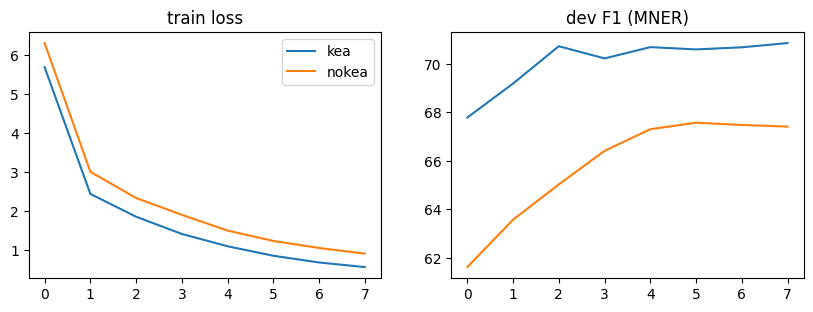

,P,R,F1
kea,76.56,77.31,76.93
nokea,67.36,67.83,67.59


Paper Table 3 – MNER F1 của MAKAR (KEA + ECA): GMNER 86.38 | FMNERG 71.24


In [10]:
import matplotlib.pyplot as plt
GOLD = load_gold(f"{tdir}/test.txt", xdir, col)
ner = {n: json.load(open(f"{RUN_DIR}/ner_{n}/result.json")) for n in runs}
PRED = {n: [[tuple(p) for p in P] for P in r["test_pred"]] for n, r in ner.items()}   # (start, end, type, conf)
if QUICK_TEST:
    GOLD, PRED = GOLD[:200], {k: v[:200] for k, v in PRED.items()}

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for n, r in ner.items():
    ax[0].plot([l["loss"] for l in r["log"]], label=n); ax[1].plot([l["dev_f1"] for l in r["log"]], label=n)
ax[0].set_title("train loss"); ax[1].set_title("dev F1 (MNER)"); ax[0].legend(); plt.show()

mner = {n: evaluate(GOLD, [[p[:3] for p in ps] for ps in P])["MNER"] for n, P in PRED.items()}
display(pd.DataFrame(mner).T.round(2))
print(f"Paper Table 3 – MNER F1 của MAKAR (KEA + ECA): GMNER 86.38 | FMNERG 71.24")

# 3. Entity Correction Agent (ECA)

$E^{Final}=\begin{cases}\text{MLLM}_{Correct}(Res, Back, I, T) & \min(p_b,p_t)<\tau\\ Res & \text{otherwise}\end{cases}$

Trước hết kiểm chứng **giả thuyết của ECA**: thực thể có độ tin cậy thấp thực sự sai nhiều hơn?

In [11]:
import numpy as np
P = PRED["kea"]
conf, ok = [], []
for s, ps in zip(GOLD, P):
    for a, b, t, c in ps:
        conf.append(c); ok.append(s["gold"].get((a, b), (None,))[0] == t)
conf, ok = np.array(conf), np.array(ok)
bins = [0, .3, .5, .7, .9, .99, 1.0001]
dfc = pd.DataFrame({"bin": pd.cut(conf, bins, right=False), "correct": ok}).groupby("bin", observed=True)["correct"].agg(["count", "mean"])
dfc["mean"] = (100 * dfc["mean"]).round(1); dfc.columns = ["#thực thể dự đoán", "precision (%)"]; display(dfc)
low_sent = [i for i, ps in enumerate(P) if any(c < TAU for *_, c in ps)]
print(f"{(conf < TAU).sum()} thực thể tin cậy thấp (< {TAU}) trong {len(low_sent)} câu; "
      f"precision nhóm thấp = {100 * ok[conf < TAU].mean():.1f}% vs nhóm cao = {100 * ok[conf >= TAU].mean():.1f}%")

,#thực thể dự đoán,precision (%)
bin,,
"[0.0, 0.3)",15,0.0
"[0.3, 0.5)",76,23.7
"[0.5, 0.7)",137,35.0
"[0.7, 0.9)",220,50.0
"[0.9, 0.99)",457,65.6
"[0.99, 1.0)",1663,89.6


91 thực thể tin cậy thấp (< 0.5) trong 84 câu; precision nhóm thấp = 19.8% vs nhóm cao = 78.6%


In [12]:
# Bước 1 – Web search (paper: Bing + ReaderLM-v2; Bing đã ngừng -> DuckDuckGo, lấy title + snippet của 3 kết quả)
import re
TYPES = ["PER", "LOC", "ORG", "OTHER"] if DATASET == "GMNER" else ner["kea"]["labels"]
TYPES = sorted({l[2:] for l in TYPES if l != "O"}) if DATASET == "FMNERG" else TYPES
low_sent = sorted(low_sent, key=lambda i: min(c for *_, c in P[i]))      # câu kém tin cậy nhất trước
eca_sent = low_sent[:ECA_MAX_SENT] if ECA_MAX_SENT else low_sent
ECA_T0 = time.time(); ECA_DEADLINE = min(DEADLINE, ECA_T0 + ECA_MAX_H * 3600)
SEARCH_FILE = f"{RUN_DIR}/eca_search.json"
search = json.load(open(SEARCH_FILE)) if os.path.exists(SEARCH_FILE) else {}

def clean(text):
    text = re.sub(r"^RT @ \S+ :", "", text); text = re.sub(r"http\S+", "", text)
    return re.sub(r"\s+", " ", text.replace("#", "").replace("@ ", "@")).strip()

import sys
DDGS = None
if RUN_ECA and not STOP:
    for attempt in range(2):
        try:
            from ddgs import DDGS; break
        except ImportError:
            try:
                from duckduckgo_search import DDGS; break
            except ImportError:
                print("cài ddgs ..."); subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ddgs"])
    if DDGS is None: print("⚠️ Không cài được ddgs -> ECA chạy KHÔNG có background knowledge từ web")
    for k, i in enumerate(eca_sent if DDGS else []):
        if str(i) in search: continue
        if time.time() > ECA_T0 + 0.25 * (ECA_DEADLINE - ECA_T0): print("hết thời gian search, dừng ở", k); break
        q = clean(" ".join(GOLD[i]["words"]))[:250]
        for attempt in range(3):
            try:
                res = DDGS().text(q, max_results=ECA_NUM_PAGES) or []
                search[str(i)] = [f"{r.get('title', '')}: {r.get('body', '')}" for r in res]; break
            except Exception as e:
                time.sleep(3 * (attempt + 1)); search[str(i)] = []
        if k % 25 == 0:
            json.dump(search, open(SEARCH_FILE, "w")); print(k, "/", len(eca_sent), "|", q[:80], "->", len(search[str(i)]), "kết quả")
    json.dump(search, open(SEARCH_FILE, "w"))
    print("câu có kết quả search:", sum(bool(search.get(str(i))) for i in eca_sent), "/", len(eca_sent))

0 / 84 | Mr Simon Bach on engaging medical students in RCTs -> 3 kết quả
25 / 84 | @harunmaruf : Outside BuloMarer , AMISOM commander Gen . Dick Olum finds a souve -> 0 kết quả
50 / 84 | Playa Carrillo is as flat as my first gf before she got her boob job . stillhitt -> 3 kết quả


h2 connection driver error: connection reset


75 / 84 | Louis Vuitton Unveils New Voyager GMT Watch : The luxury house is positioning th -> 3 kết quả
câu có kết quả search: 70 / 84


In [13]:
# Bước 2 – Tóm tắt background knowledge (MLLM) ; Bước 3 – sửa thực thể tin cậy thấp (MLLM + ảnh)
# Prompt theo Appendix H ("Correcting Low-Confidence Entity"), thêm yêu cầu định dạng đầu ra để parse tự động.
from huggingface_hub import snapshot_download as hf_download
def fmt_ents(ps): return ", ".join(f"[{' '.join(w[a:b])}, {t}]" for a, b, t, *_ in ps)

def _model_gb(d):
    return sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(d) for f in fs if f.endswith(".safetensors")) / 1e9

VLLM_OK = BACKEND in ("auto", "vllm") and subprocess.run([sys.executable, "-c", "import vllm"], capture_output=True).returncode == 0
print("vLLM khả dụng:", VLLM_OK)

def _load(path):
    r = {}
    if os.path.exists(path):
        for l in open(path):
            try: j = json.loads(l); r[j["id"]] = j["outputs"]
            except json.JSONDecodeError: pass
    return r

def run_mllm(model_dir, reqs, out, extra="", deadline=None):
    """Chạy mllm_infer.py trong tiến trình con. Không có vLLM -> transformers, model nhỏ thì mỗi GPU một tiến trình.
    Kết quả ghi vào out.shard*.jsonl, chạy lại sẽ tiếp tục từ chỗ dừng. Dừng (giữ kết quả dở dang) tại `deadline`."""
    global STOP
    deadline = min(deadline or DEADLINE, DEADLINE - 600)
    shard_files = lambda: sorted(glob.glob(out.replace(".jsonl", ".shard*.jsonl")))
    res = {}
    for f in shard_files(): res.update(_load(f))
    todo = [r for r in reqs if r["id"] not in res]
    print(f"{len(reqs) - len(todo)} kết quả có sẵn, cần chạy {len(todo)} request")
    if todo:
        gb = _model_gb(model_dir) * (2 if "float32" in extra else 1)
        n_shard = 1 if VLLM_OK or N_GPU < 2 or gb > 12 else N_GPU
        print(f"backend: {'vLLM (TP=%d)' % TP if VLLM_OK else f'transformers × {n_shard} tiến trình'} | model {gb:.1f} GB")
        procs = []
        for k in range(n_shard):
            stem = out.replace(".jsonl", f".shard{k}")
            with open(stem + ".in", "w") as f: f.write("".join(json.dumps(r) + "\n" for r in todo[k::n_shard]))
            env = f"CUDA_VISIBLE_DEVICES={k} " if n_shard > 1 else ""
            cmd = (f"{env}VLLM_USE_V1=0 {sys.executable} mllm_infer.py --model {model_dir} --inp {stem}.in --out {stem}.jsonl "
                   f"--backend {'vllm' if VLLM_OK else 'hf'} --tp {TP} --deadline {deadline} {extra}")
            procs.append((subprocess.Popen(cmd, shell=True, stdout=open(stem + ".log", "w"), stderr=subprocess.STDOUT), stem + ".log"))
        while any(p.poll() is None for p, _ in procs):
            time.sleep(60)
            prog = [([l.strip() for l in open(lg) if re.match(r"^\d+/\d+ ", l)] or ["đang nạp model..."])[-1] for _, lg in procs]
            print(time.strftime("%H:%M"), " | ".join(prog))
        for p, lg in procs:
            if p.returncode:
                print(f"❌ tiến trình lỗi, xem {lg}:\n" + "".join(l for l in open(lg).readlines()[-30:] if "warn" not in l.lower()))
        for f in shard_files(): res.update(_load(f))
    missing = sum(r["id"] not in res for r in reqs)
    if missing and time.time() >= DEADLINE - 900:
        STOP = True; print(f"⏱ hết ngân sách thời gian, còn thiếu {missing}/{len(reqs)} kết quả (đã lưu phần đã chạy).")
    elif reqs and missing == len(reqs) and time.time() < deadline:
        raise RuntimeError("Không có kết quả nào từ MLLM — xem log lỗi ở trên.")
    elif missing: print(f"⚠️ thiếu {missing}/{len(reqs)} kết quả (chạm trần thời gian của bước này)")
    print(f"Còn {hours_left():.1f} h trong ngân sách thời gian")
    return res

if RUN_ECA and not STOP:
    eca_dir = hf_download(ECA_MODEL, local_dir=f"{CACHE}/{ECA_MODEL.split('/')[-1]}")
    sum_reqs = []
    for i in eca_sent:
        w = GOLD[i]["words"]; low = [p for p in P[i] if p[3] < TAU]
        sum_reqs.append({"id": str(i), "image": None, "prompt":
            f"Candidate Entity: {fmt_ents(low)}\nInput Text: {' '.join(w)}\nSearch results:\n" +
            "\n".join(f"- {x[:500]}" for x in search.get(str(i), [])) +
            "\nTask: Summarize, in at most 100 words, the background knowledge in the search results that helps to "
            "determine the correct boundaries and types of the candidate entities. If nothing is relevant, say so."})
    summ = run_mllm(eca_dir, sum_reqs, f"{RUN_DIR}/eca_summary.jsonl", "--max_tokens 200",
                    deadline=time.time() + 0.4 * (ECA_DEADLINE - time.time()))

    type_doc = ("PER (person, fictional character); LOC (country, city, geographical location); "
                "ORG (club, company, party, school, news organization); OTHER (events, products, works, concepts, other)"
                if DATASET == "GMNER" else ", ".join(TYPES))
    cor_reqs = []
    for i in eca_sent:
        w = GOLD[i]["words"]
        cor_reqs.append({"id": str(i), "image": IMG.get(GOLD[i]["img"]), "prompt":
            f"Background Knowledge: {summ.get(str(i), [''])[0]}\n"
            f"KEA Results: {fmt_ents(P[i])}\n"
            f"Low-confidence entities: {fmt_ents([p for p in P[i] if p[3] < TAU])}\n"
            f"Input Text: {' '.join(w)}\n"
            "Task: Based on the background knowledge retrieved from web search, along with results from KEA, the input image, "
            "and text, please refine the entity boundaries and types of the low-confidence entities.\n"
            f"Entity types: {type_doc}.\n"
            "Notes: The goal is to use this background knowledge to address semantic ambiguity and improve the accuracy of "
            "named entity recognition. Copy entity names exactly from the Input Text; words beginning with @ are not entities.\n"
            "Give a brief explanation, then a last line in the format\n"
            "Final entities: [entity name, TYPE], [entity name, TYPE], ..."})
    corr = run_mllm(eca_dir, cor_reqs, f"{RUN_DIR}/eca_correct.jsonl", "--max_tokens 400 --dtype half", deadline=ECA_DEADLINE)
    if DELETE_MODELS and ECA_MODEL != RAW_BASELINE: shutil.rmtree(eca_dir, ignore_errors=True)
    print(cor_reqs[0]["prompt"][:1500], "\n--- OUTPUT ---\n", corr.get(cor_reqs[0]["id"], [""])[0])

vLLM khả dụng: False


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

0 kết quả có sẵn, cần chạy 84 request
backend: transformers × 2 tiến trình | model 7.5 GB
06:15 đang nạp model... | đang nạp model...
06:16 42/42  64s | 42/42  57s
Còn 9.2 h trong ngân sách thời gian
0 kết quả có sẵn, cần chạy 84 request
backend: transformers × 2 tiến trình | model 7.5 GB
06:17 đang nạp model... | đang nạp model...
06:18 42/42  102s | 42/42  107s
Còn 9.2 h trong ngân sách thời gian
Background Knowledge: The search results provide information about Simon Bach's role as a consultant colorectal surgeon and his involvement in clinical trials. However, they do not directly address the specific topic of engaging medical students in RCTs. Therefore, there is no direct relevance to the candidate entity "RCTs" or "location_other."
KEA Results: [Mr Simon Bach, intellectual], [RCTs, location_other]
Low-confidence entities: [RCTs, location_other]
Input Text: RT @ STARSurgUK : Mr Simon Bach on engaging medical students in RCTs
Task: Based on the background knowledge retrieved from 

In [14]:
# Bước 4 – ghép kết quả theo Eq. 7: giữ nguyên thực thể tin cậy cao, thay thực thể tin cậy thấp bằng kết quả của MLLM
def norm_type(t):
    t = t.strip().strip("'\"")
    if DATASET == "GMNER":
        t = t.upper(); return {"MISC": "OTHER", "PERSON": "PER", "LOCATION": "LOC", "ORGANIZATION": "ORG"}.get(t, t)
    t = t.lower().replace(" ", "_").replace("-", "_")
    for c in ("location_", "building_", "organization_", "person_", "art_", "event_", "product_", "other_"):
        if t.startswith(c) and t[len(c):] in TYPES: t = t[len(c):]
    return t

def find_span(words, name, near):
    toks = name.split(); n = len(toks); low = [x.lower().lstrip("#") for x in words]
    hits = [k for k in range(len(words) - n + 1) if low[k:k + n] == [x.lower().lstrip("#") for x in toks]]
    if not hits: return None
    return min(hits, key=lambda k: min(abs(k - a) for a, b in near) if near else 0)

def merge(i, ps, out):
    high = [p[:3] for p in ps if p[3] >= TAU]; low = [p[:3] for p in ps if p[3] < TAU]
    m = out.rsplit("Final entities:", 1)
    if len(m) < 2: return [p[:3] for p in ps], False          # không parse được -> giữ nguyên
    new = []
    for name, t in re.findall(r"\[\s*([^\[\],]+?)\s*,\s*([^\[\],]+?)\s*\]", m[1]):
        t = norm_type(t); k = find_span(GOLD[i]["words"], name.strip().strip("'\""), [(a, b) for a, b, _ in low])
        if t not in TYPES or k is None: continue
        span = (k, k + len(name.split()), t)
        overl = lambda x, y: x[0] < y[1] and y[0] < x[1]
        if any(overl(span, h) for h in high): continue
        if not ECA_ALLOW_NEW and not any(overl(span, l) for l in low): continue
        if span not in new: new.append(span)
    return sorted(high + new), True

FINAL = [[p[:3] for p in ps] for ps in P]
if RUN_ECA and "corr" in globals():
    n_parsed = n_changed = 0
    for i in eca_sent:
        out = corr.get(str(i), [""])[0]
        FINAL[i], parsed = merge(i, P[i], out); n_parsed += parsed
        n_changed += sorted(FINAL[i]) != sorted(p[:3] for p in P[i])
    print(f"ECA: parse được {n_parsed}/{len(eca_sent)} câu, thay đổi {n_changed} câu")
    for i in [i for i in eca_sent if sorted(FINAL[i]) != sorted(p[:3] for p in P[i])][:8]:
        w = GOLD[i]["words"]; f = lambda ps: [(" ".join(w[a:b]), t) for a, b, t, *_ in ps]
        print("\nTEXT:", " ".join(w)); print("  KEA :", f(P[i])); print("  ECA :", f(FINAL[i]))
        print("  GOLD:", [(" ".join(w[a:b]), t) for (a, b), (t, _) in GOLD[i]["gold"].items()])
mner_eca = {"KEA (w/o ECA)": evaluate(GOLD, [[p[:3] for p in ps] for ps in P])["MNER"], "KEA + ECA": evaluate(GOLD, FINAL)["MNER"]}
display(pd.DataFrame(mner_eca).T.round(2))

ECA: parse được 84/84 câu, thay đổi 46 câu

TEXT: RT @ tim _ cook : Today Apple and IBM announced a landmark enterprise partnership . Thanks Ginni ! # Apple # IBM
  KEA : [('Apple', 'company'), ('IBM', 'company'), ('Ginni', 'businessman'), ('Apple', 'company'), ('IBM', 'company')]
  ECA : [('Apple', 'company'), ('IBM', 'company'), ('Apple', 'company'), ('IBM', 'company')]
  GOLD: [('tim _ cook', 'businessman'), ('Apple', 'company'), ('IBM', 'company')]

TEXT: How Kingfisher inspired the redesign of the sleeker Japanese Bullet Train http://t. co/4spuvRw1cO @ NYSERDA # biomimicry
  KEA : [('Kingfisher', 'product_other'), ('Japanese Bullet Train', 'product_other')]
  ECA : [('Kingfisher', 'animal'), ('Japanese Bullet Train', 'product_other')]
  GOLD: [('Kingfisher', 'animal'), ('Japanese Bullet Train', 'product_other')]

TEXT: Rtlatenitevibe : RT EDMOnEarth : You ' re at a festival and the only toilet paper has this written on it . What you doi …
  KEA : [('EDMOnEarth', 'journalist')]
  E

,P,R,F1
KEA (w/o ECA),76.56,77.31,76.93
KEA + ECA,77.13,77.31,77.22


# 4. Entity Reasoning Grounding Agent (ERGA)

Mỗi thực thể dự đoán được hỏi riêng bằng prompt **nguyên văn dữ liệu huấn luyện của tác giả** (`grounding_data/sample_*_3k.json`):

```
<image>Comprehensively analyze the Text and the Image.
Text: {text}
Is "{entity} (is a/an {type})" present in the image? If yes, provide its coordinates; else return [0,0,0,0]. ...
```
Mô hình trả lời `<think> … </think> <answer>[x1, y1, x2, y2]</answer>` với tọa độ pixel của ảnh gốc
(đã kiểm tra: 2522/2679 đáp án trong dữ liệu train trùng khớp box XML gốc).

Checkpoint chính thức `MAKAR-3B/7B` = Qwen2.5-VL sau **SFT cold-start (3k easy CoT) → GRPO (3k hard)**.
Để tiết kiệm thời gian, ta grounding một lần cho **hợp** các tập thực thể của mọi biến thể (KEA, KEA+ECA, w/o KEA).

In [15]:
if STOP:
    print(SKIP_MSG)
else:
    from modelscope import snapshot_download as ms_download
    from PIL import Image
    makar_dir = ms_download(MAKAR_CKPT, cache_dir=f"{CACHE}/ms")

    COARSE = {}   # FMNERG: loại mịn -> loại thô
    if DATASET == "FMNERG":
        for l in open(f"{tdir}/train.txt"):
            p = l.rstrip("\n").split("\t")
            if len(p) == 3 and p[2] != "O": COARSE[p[2][2:]] = p[1][2:]
    def type_desc(t):
        if DATASET == "GMNER": return GMNER_TYPE_WORD[t]
        c = COARSE.get(t, "other")
        return c if t.endswith("other") else f"{c}, {t.replace('_', ' ')}"   # vd. "person, athlete"; "event" cho event_other

    variants = {"MAKAR (KEA+ECA+ERGA)": FINAL, "w/o ECA": [[p[:3] for p in ps] for ps in PRED["kea"]]}
    if "nokea" in PRED: variants["w/o KEA"] = [[p[:3] for p in ps] for ps in PRED["nokea"]]
    SIZE = {}
    def img_size(i):
        if i not in SIZE:
            p = IMG.get(GOLD[i]["img"])
            SIZE[i] = Image.open(p).size if p else None
        return SIZE[i]
    queries = {}
    for V in variants.values():
        for i, ps in enumerate(V):
            for a, b, t in ps:
                qid = f"{i}|{a}|{b}|{t}"
                if qid in queries or img_size(i) is None: continue
                queries[qid] = {"id": qid, "image": IMG[GOLD[i]["img"]],
                                "prompt": grounding_prompt(" ".join(GOLD[i]["words"]), " ".join(GOLD[i]["words"][a:b]), type_desc(t))}
    print(len(queries), "truy vấn grounding")
    print(list(queries.values())[0]["prompt"])

2026-10-13 06:18:13,653 | INFO    | modelscope_hub.download | Downloading 16 files from soliton110/MAKAR-3B@master


Downloading:   0%|          | 0/16 [00:00<?, ?file/s]

chat_template.json: 0.00B [00:00, ?B/s]

README.md:   0%|          | 0.00/3.27k [00:00<?, ?B/s]

.gitattributes:   0%|          | 0.00/2.31k [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

3151 truy vấn grounding
Comprehensively analyze the Text and the Image.
Text: The geometry of plants . Garfield Park Conservatory

Is "Garfield Park Conservatory (is a/an location, park)" present in the image? If yes, provide its coordinates; else return [0,0,0,0].
Notion:
Please ignore the text content in the image (such as titles, tags, text boxes, etc.) and only focus on non-text visual elements (such as people, objects, logos, etc.).


In [16]:
def attach(V, outs):
    res = []
    for i, ps in enumerate(V):
        res.append([(a, b, t, parse_box(outs.get(f"{i}|{a}|{b}|{t}", [""])[0], img_size(i))) for a, b, t in ps])
    return res
PAPER = {"GMNER": {"MNERG": 71.88, "MNER": 86.38, "EEG": 74.64}, "FMNERG": {"MNERG": 60.54, "MNER": 71.24, "EEG": 75.66}}

if STOP:
    print(SKIP_MSG)
else:
    t0 = time.time()
    G_OUT = run_mllm(makar_dir, list(queries.values()), f"{RUN_DIR}/ground_{MAKAR_CKPT.split('/')[-1]}.jsonl",
                     f"--max_tokens 512 --dtype {MLLM_DTYPE}")
    print(f"{len(G_OUT)}/{len(queries)} kết quả, {time.time() - t0:.0f}s")
if not STOP:
    fmt_ok = np.mean([format_reward(o[0]) for o in G_OUT.values()])
    print(f"Tỉ lệ output đúng định dạng <think>…</think><answer>…</answer>: {100 * fmt_ok:.1f}%")
    if fmt_ok < 0.5: print("⚠️ Tỉ lệ thấp bất thường -> có thể fp16 bị tràn số trên T4: đặt MLLM_DTYPE='float32', xóa file ground_*.shard*.jsonl rồi chạy lại.")
    k0 = next(iter(G_OUT)); print(k0, "\n", G_OUT[k0][0])
    RESULTS = {name: evaluate(GOLD, attach(V, G_OUT)) for name, V in variants.items()}
    tab = pd.DataFrame({n: {m: r[m]["F1"] for m in ("MNERG", "MNER", "EEG")} for n, r in RESULTS.items()}).T.round(2)
    display(tab)
    print("Paper Table 3 (MAKAR):", PAPER[DATASET])

0 kết quả có sẵn, cần chạy 3151 request
backend: transformers × 2 tiến trình | model 8.1 GB
06:22 đang nạp model... | đang nạp model...
06:23 40/1576  80s | 40/1575  83s
06:24 80/1576  154s | 80/1575  164s
06:25 120/1576  225s | 80/1575  164s
06:26 120/1576  225s | 120/1575  257s
06:27 160/1576  309s | 160/1575  335s
06:28 200/1576  387s | 160/1575  335s
06:29 240/1576  463s | 200/1575  418s
06:30 240/1576  463s | 240/1575  518s
06:31 280/1576  566s | 240/1575  518s
06:32 320/1576  648s | 280/1575  615s
06:33 320/1576  648s | 320/1575  699s
06:34 360/1576  742s | 320/1575  699s
06:35 360/1576  742s | 360/1575  789s
06:36 400/1576  834s | 400/1575  880s
06:37 440/1576  923s | 400/1575  880s
06:38 480/1576  1010s | 440/1575  976s
06:39 480/1576  1010s | 480/1575  1051s
06:40 520/1576  1098s | 480/1575  1051s
06:41 560/1576  1185s | 520/1575  1134s
06:42 560/1576  1185s | 560/1575  1217s
06:43 600/1576  1272s | 600/1575  1303s
06:44 640/1576  1359s | 600/1575  1303s
06:45 640/1576  1359s 

,MNERG,MNER,EEG
MAKAR (KEA+ECA+ERGA),63.75,77.22,73.57
w/o ECA,63.51,76.93,73.57
w/o KEA,56.00,67.59,71.94


Paper Table 3 (MAKAR): {'MNERG': 60.54, 'MNER': 71.24, 'EEG': 75.66}


### Baseline *Raw* Qwen2.5-VL (Table 5)
Cùng prompt, cùng thực thể, nhưng dùng Qwen2.5-VL-Instruct chưa qua SFT/GRPO → thấy rõ tác dụng của huấn luyện suy luận 2 pha.

In [17]:
import random
if STOP:
    print(SKIP_MSG)
elif RAW_BASELINE:
    raw_name = RAW_BASELINE.split('/')[-1]
    raw_dir = hf_download(RAW_BASELINE, local_dir=f"{CACHE}/{raw_name}")
    random.seed(0)
    sub = sorted(random.sample(range(len(GOLD)), min(RAW_MAX_SENT or len(GOLD), len(GOLD))))
    qids = {i: [f"{i}|{a}|{b}|{t}" for a, b, t in FINAL[i]] for i in sub}
    final_q = [queries[q] for i in sub for q in qids[i] if q in queries]
    RAW_OUT = run_mllm(raw_dir, final_q, f"{RUN_DIR}/ground_raw_{raw_name}.jsonl", f"--max_tokens 512 --dtype {MLLM_DTYPE}",
                       deadline=time.time() + RAW_MAX_H * 3600)
    done = [i for i in sub if all(q in RAW_OUT or q not in queries for q in qids[i])]   # chỉ đánh giá câu đã chạy xong
    if done:
        A_m, A_r = attach(FINAL, G_OUT), attach(FINAL, RAW_OUT)
        RESULTS[f"MAKAR – tập con {len(done)} câu"] = evaluate([GOLD[i] for i in done], [A_m[i] for i in done])
        RESULTS[f"Raw {raw_name} – cùng tập con"] = evaluate([GOLD[i] for i in done], [A_r[i] for i in done])
        k0 = next(iter(RAW_OUT)); print("Ví dụ output raw:", RAW_OUT[k0][0][:500])
    if DELETE_MODELS: shutil.rmtree(raw_dir, ignore_errors=True)
if not STOP:
    tab = pd.DataFrame({n: {m: r[m]["F1"] for m in ("MNERG", "MNER", "EEG")} for n, r in RESULTS.items()}).T.round(2)
    display(tab)
    print("Paper Table 5 (EEG): Qwen2.5-VL-3B Raw 22.45 / 38.38 | MAKAR-3B 72.48 / 72.43 | Qwen2.5-VL-7B Raw 60.09 / 60.05 | MAKAR-7B 74.64 / 75.66  (GMNER / FMNERG)")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

0 kết quả có sẵn, cần chạy 504 request
backend: transformers × 2 tiến trình | model 7.5 GB
07:35 80/252  39s | 80/252  45s
07:36 160/252  86s | 160/252  98s
07:37 240/252  164s | 200/252  127s
07:38 240/252  164s | 240/252  177s
07:39 252/252  234s | 252/252  247s
Còn 7.8 h trong ngân sách thời gian
Ví dụ output raw: [0,0,392,196]


,MNERG,MNER,EEG
MAKAR (KEA+ECA+ERGA),63.75,77.22,73.57
w/o ECA,63.51,76.93,73.57
w/o KEA,56.00,67.59,71.94
MAKAR – tập con 300 câu,64.09,78.14,74.98
Raw Qwen2.5-VL-3B-Instruct – cùng tập con,20.57,78.14,23.54


Paper Table 5 (EEG): Qwen2.5-VL-3B Raw 22.45 / 38.38 | MAKAR-3B 72.48 / 72.43 | Qwen2.5-VL-7B Raw 60.09 / 60.05 | MAKAR-7B 74.64 / 75.66  (GMNER / FMNERG)


### Minh họa GRPO (Eq. 9–12) trên mẫu thật
Với mỗi input, policy sinh nhóm $G$ response $o_i\sim\pi_\theta(o|I,T,Q)$; reward
$r = \alpha\, r_{format} + (1-\alpha)\, r_{acc}$ với $\alpha=0.5$, $r_{acc}=\mathbb 1[\text{IoU}>0.5]$;
advantage chuẩn hóa trong nhóm $A_i=\frac{r_i-\text{mean}(r)}{\text{std}(r)}$.
Ta lấy mẫu $G=5$ response (temperature 1.0, top-p 0.99 như config EasyR1 của tác giả) từ checkpoint MAKAR cho vài thực thể vàng.
Nhóm có reward đồng đều ⇒ $A_i=0$ ⇒ không có tín hiệu học: lý do tác giả dành GRPO cho mẫu **khó** (Table 6).

In [18]:
if STOP:
    print(SKIP_MSG)
else:
    import random
    random.seed(0)
    cand = [(i, a, b, t, bx) for i, s in enumerate(GOLD) for (a, b), (t, bx) in s["gold"].items() if img_size(i)]
    demo = random.sample([c for c in cand if c[4]], 4) + random.sample([c for c in cand if not c[4]], 2)
    dreq = [{"id": f"{i}|{a}|{b}|{t}", "image": IMG[GOLD[i]["img"]],
             "prompt": grounding_prompt(" ".join(GOLD[i]["words"]), " ".join(GOLD[i]["words"][a:b]), type_desc(t))} for i, a, b, t, _ in demo]
    D_OUT = run_mllm(makar_dir, dreq, f"{RUN_DIR}/grpo_demo.jsonl",
                     f"--n {GRPO_DEMO_N} --temperature 1.0 --top_p 0.99 --max_tokens 512 --dtype {MLLM_DTYPE}")
    rows = []
    for i, a, b, t, bx in demo:
        outs = D_OUT.get(f"{i}|{a}|{b}|{t}", [])
        r = np.array([grpo_reward(o, bx[0] if bx else None) for o in outs])
        A = (r - r.mean()) / (r.std() + 1e-6)
        for k, o in enumerate(outs):
            rows.append({"entity": " ".join(GOLD[i]["words"][a:b]), "gold box": bx[0] if bx else None, "k": k,
                         "pred": parse_box(o, img_size(i)), "r_format": format_reward(o),
                         "r_acc": accuracy_reward(o, bx[0] if bx else None), "r": r[k], "A_i": round(A[k], 2)})
    display(pd.DataFrame(rows))

0 kết quả có sẵn, cần chạy 6 request
backend: transformers × 2 tiến trình | model 8.1 GB
07:40 3/3  41s | đang nạp model...
07:41 3/3  41s | 3/3  63s
Còn 7.8 h trong ngân sách thời gian


,entity,gold box,k,pred,r_format,r_acc,r,A_i
0,Donald Trump,"[5, 380, 534, 803]",0,"[5.0, 493.0, 600, 802.0]",1.0,1.0,1.0,0.0
1,Donald Trump,"[5, 380, 534, 803]",1,"[8.0, 401.0, 600.0, 794.0]",1.0,1.0,1.0,0.0
2,Donald Trump,"[5, 380, 534, 803]",2,"[8.0, 396.0, 600, 799.0]",1.0,1.0,1.0,0.0
3,Donald Trump,"[5, 380, 534, 803]",3,"[7.0, 415.0, 600, 797.0]",1.0,1.0,1.0,0.0
4,Donald Trump,"[5, 380, 534, 803]",4,"[3.0, 420.0, 600, 797.0]",1.0,1.0,1.0,0.0
5,Charles Bronfman,"[124, 326, 261, 472]",0,"[119.0, 342.0, 258.0, 469.0]",1.0,1.0,1.0,0.0
6,Charles Bronfman,"[124, 326, 261, 472]",1,"[117.0, 342.0, 258.0, 470.0]",1.0,1.0,1.0,0.0
7,Charles Bronfman,"[124, 326, 261, 472]",2,"[123.0, 342.0, 253.0, 467.0]",1.0,1.0,1.0,0.0
8,Charles Bronfman,"[124, 326, 261, 472]",3,"[120.0, 338.0, 259.0, 473.0]",1.0,1.0,1.0,0.0
9,Charles Bronfman,"[124, 326, 261, 472]",4,"[120.0, 342.0, 257.0, 467.0]",1.0,1.0,1.0,0.0


### Case study (giống Fig. 6)
Box xanh lá = nhãn vàng, box đỏ = MAKAR; kèm đoạn suy luận `<think>`.

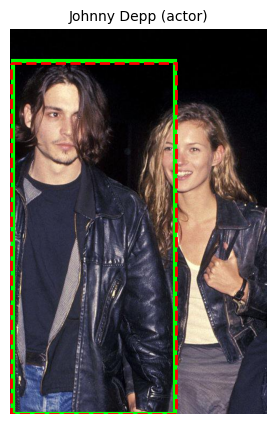

TEXT: RT @ SlLVERSCREENS : Johnny Depp and Kate Moss ( 1994-1997 )
<think>
The image shows two individuals standing close together, both dressed in leather jackets. The person on the left, identified as Johnny Depp based on the text provided, is wearing a dark blue leather jacket over a black shirt and jeans. His hair is long and dark, and he has a beard. The person on the right appears to be Kate Moss, as indicated by the text. She is wearing a black leather jacket over a white top and gray pants.
</think> 
 <answer>[2, 64, 310, 728]</answer> 



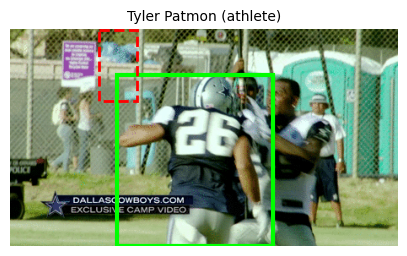

TEXT: RT @ dallascowboys : Dez Bryant - Tyler Patmon Fight Full Video &amp ; Reaction MUST WATCH :
<think>
The image shows two football players on a field, one wearing a dark blue jersey with the number 26 and the other in a white jersey. The player in the white jersey appears to be Tyler Patmon based on the context provided by the text. The text mentions "Tyler Patmon Fight Full Video & Reaction," which suggests that there was a physical altercation involving these two players. The player in the white jersey seems to be involved in the interaction, as indicated by his body orientation and the context of the text.
</think> 
 <answer>[105, 1, 150, 85]</answer> 



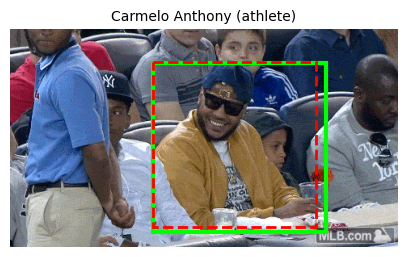

TEXT: RT @ benchwarmerdan : Justise Winslow and Carmelo Anthony were at the Yankees game together .
<think>
The image shows a group of people sitting in what appears to be a stadium setting, likely attending a sports event. The text mentions that Justise Winslow and Carmelo Anthony were at the Yankees game together. Given this context, it is reasonable to infer that the person in the image who is wearing a yellow jacket and sunglasses is Carmelo Anthony, as he is known to be a professional basketball player who has been associated with the New York Yankees baseball team.
</think> 
 <answer>[177, 40, 378, 245]</answer> 



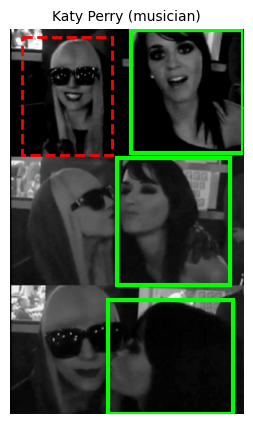

TEXT: 👑 Katy Perry and Lady Gaga appreciation tweet 👑
<think>
The image provided is a collage of four photographs featuring two individuals. The text "👑 Katy Perry and Lady Gaga appreciation tweet 👑" suggests that the individuals in the images are Katy Perry and Lady Gaga, as indicated by the crown emojis used to denote their status or significance.

Given this context:
1. The first and third photographs show an individual with long hair wearing sunglasses, which aligns with the description of Katy Perry, known for her distinctive hairstyle and fashion choices.
2. The second and fourth photographs show another individual with dark hair, which matches the description of Lady Gaga, another well-known musician and performer.

Based on the text and 



In [19]:
if STOP:
    print(SKIP_MSG)
else:
    import matplotlib.patches as patches
    best = attach(FINAL, G_OUT)
    show = [(i, p) for i, ps in enumerate(best) for p in ps if p[3] is not None and (p[0], p[1]) in GOLD[i]["gold"] and GOLD[i]["gold"][(p[0], p[1])][1]]
    random.seed(1)
    for i, (a, b, t, box) in random.sample(show, min(4, len(show))):
        w = GOLD[i]["words"]; fig, ax = plt.subplots(figsize=(5, 5))
        ax.imshow(Image.open(IMG[GOLD[i]["img"]]).convert("RGB"))
        for g in GOLD[i]["gold"][(a, b)][1]:
            ax.add_patch(patches.Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, ec="lime", lw=3))
        ax.add_patch(patches.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], fill=False, ec="red", lw=2, ls="--"))
        ax.set_title(f"{' '.join(w[a:b])} ({t})", fontsize=10); ax.axis("off"); plt.show()
        print("TEXT:", " ".join(w)); print(G_OUT[f"{i}|{a}|{b}|{t}"][0][:700], "\n")

# 5. Tổng hợp & so sánh với paper

In [20]:
if STOP:
    print(SKIP_MSG)
else:
    summary = {n: {m: round(r[m]["F1"], 2) for m in ("MNERG", "MNER", "EEG")} for n, r in RESULTS.items()}
    json.dump({"dataset": DATASET, "config": {"NER_EPOCHS": NER_EPOCHS, "GMNER_TRAIN_MODE": GMNER_TRAIN_MODE, "MAKAR_CKPT": MAKAR_CKPT,
               "RUN_ECA": RUN_ECA, "QUICK_TEST": QUICK_TEST}, "results": summary,
               "full": RESULTS}, open(f"{WORK}/results_{DATASET}.json", "w"), indent=1)

    PAPER_ALL = {
      ("Table 3", "MAKAR (KEA+ECA+ERGA)"): {"GMNER": {"MNERG": 71.88, "MNER": 86.38, "EEG": 74.64}, "FMNERG": {"MNERG": 60.54, "MNER": 71.24, "EEG": 75.66}},
      ("Table 4", "w/o KEA"): {"GMNER": {"MNERG": 67.63}, "FMNERG": {"MNERG": 57.50}},
      ("Table 4", "w/o ECA"): {"GMNER": {"MNERG": 69.23}, "FMNERG": {"MNERG": 58.57}},
      ("Table 5", "Raw Qwen2.5-VL-3B-Instruct"): {"GMNER": {"EEG": 22.45}, "FMNERG": {"EEG": 38.38}},
    }
    rows = []
    for f in sorted(glob.glob(f"{WORK}/results_*.json")):
        R = json.load(open(f)); ds = R["dataset"]
        for (tb, name), pv in PAPER_ALL.items():
            ours = next((v for k, v in R["results"].items() if k.startswith(name.split(" (")[0])), {})
            for m, v in pv.get(ds, {}).items():
                rows.append({"Dataset": ds, "Bảng": tb, "Hệ thống": name, "Metric": m, "Paper": v,
                             "Tái lập": ours.get(m), "Δ": None if ours.get(m) is None else round(ours[m] - v, 2)})
    final_tab = pd.DataFrame(rows); display(final_tab)
    final_tab.to_csv(f"{WORK}/comparison.csv", index=False)
    print("Đã lưu:", f"{WORK}/results_{DATASET}.json", f"{WORK}/comparison.csv")

,Dataset,Bảng,Hệ thống,Metric,Paper,Tái lập,Δ
0,FMNERG,Table 3,MAKAR (KEA+ECA+ERGA),MNERG,60.54,63.75,3.21
1,FMNERG,Table 3,MAKAR (KEA+ECA+ERGA),MNER,71.24,77.22,5.98
2,FMNERG,Table 3,MAKAR (KEA+ECA+ERGA),EEG,75.66,73.57,-2.09
3,FMNERG,Table 4,w/o KEA,MNERG,57.50,56.00,-1.50
4,FMNERG,Table 4,w/o ECA,MNERG,58.57,63.51,4.94
5,FMNERG,Table 5,Raw Qwen2.5-VL-3B-Instruct,EEG,38.38,23.54,-14.84


Đã lưu: /kaggle/working/results_FMNERG.json /kaggle/working/comparison.csv


## Gợi ý thảo luận khi thuyết trình
1. **Table 2 tái lập chính xác** từ dữ liệu gốc → đảm bảo cùng tập test và cùng định nghĩa thực thể/box.
2. **KEA:** so sánh MNER F1 giữa `kea` và `nokea` → đóng góp của auxiliary knowledge do MLLM sinh (paper: −4.25 MNERG trên GMNER khi bỏ KEA).
   Lưu ý: ta dùng lại auxiliary knowledge tác giả đã sinh sẵn; file train GMNER gốc của tác giả có 28k câu, trộn Twitter-2015/2017 và **trùng 43 câu tập test** (notebook mặc định loại bỏ, xem ô chuẩn bị dữ liệu).
3. **ECA:** bảng precision theo độ tin cậy cho thấy thực thể dưới ngưỡng τ sai nhiều hơn hẳn → hợp lý để chỉ gọi search + MLLM cho nhóm này. Kết quả phụ thuộc mạnh vào công cụ search (Bing trong paper đã ngừng hoạt động).
4. **ERGA:** khoảng cách lớn giữa Raw Qwen2.5-VL và MAKAR trên EEG minh họa tác dụng của SFT cold-start + GRPO; demo GRPO cho thấy cách reward (format + IoU) tạo advantage trong nhóm.
5. **Sai khác so với paper** có thể đến từ: số epoch NER ít hơn (10 vs 25), không dùng dữ liệu train mở rộng, search engine khác, suy luận fp16 trên T4, checkpoint 3B thay vì 7B.